<a href="https://colab.research.google.com/github/varshini-svg/BigNet-CaseStudy/blob/main/DDOS_Attack_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import Datasets from Kaggle

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mastole/ddos-ciciot2023")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ddos-ciciot2023' dataset.
Path to dataset files: /kaggle/input/ddos-ciciot2023


Step 2: Load MULTIPLE FILES to avoid dataset limitation

In [ ]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

path = "/kaggle/input/ddos-ciciot2023/*.csv"
files = glob.glob(path)

df_list = [pd.read_csv(f) for f in files[:10]]
df = pd.concat(df_list, ignore_index=True)

print("Dataset shape:", df.shape)
print("Total files available:", len(files))

Dataset shape: (2108309, 47)
Total files available: 169


Step 3: Data Cleaning

In [ ]:
# Checking for missing values
print("Missing values:\n", df.isnull().sum())

# Check duplicates BEFORE removing
print("Duplicate rows:", df.duplicated().sum())

# Cleaning
df = df.dropna()
df = df.drop_duplicates()

print("After cleaning:", df.shape)

Missing values:
 flow_duration      0
Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
Drate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
urg_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
label            

Step 4: Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize encoder
le = LabelEncoder()

# Apply encoding
df['label_encoded'] = le.fit_transform(df['label'])

# Display mapping (VERY IMPORTANT)
print("Label Encoding Mapping:\n")
for i, label in enumerate(le.classes_):
    print(f"{label} → {i}")

# Define input and output
X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

# Confirm shapes
print("\nInput shape:", X.shape)
print("Output shape:", y.shape)
print("Number of classes:", len(le.classes_))

Label Encoding Mapping:

BenignTraffic → 0
DDoS-ACK_Fragmentation → 1
DDoS-HTTP_Flood → 2
DDoS-ICMP_Flood → 3
DDoS-ICMP_Fragmentation → 4
DDoS-PSHACK_Flood → 5
DDoS-RSTFINFlood → 6
DDoS-SYN_Flood → 7
DDoS-SlowLoris → 8
DDoS-SynonymousIP_Flood → 9
DDoS-TCP_Flood → 10
DDoS-UDP_Flood → 11
DDoS-UDP_Fragmentation → 12

Input shape: (2108309, 46)
Output shape: (2108309,)
Number of classes: 13


Step 5: Dataset Description

In [ ]:
print("\nDataset Info:\n")
print(df.info())

print("\nStatistical Summary:\n")
print(df.describe().T)



Dataset Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2108309 entries, 0 to 2108308
Data columns (total 48 columns):
 #   Column           Dtype  
---  ------           -----  
 0   flow_duration    float64
 1   Header_Length    float64
 2   Protocol Type    float64
 3   Duration         float64
 4   Rate             float64
 5   Srate            float64
 6   Drate            float64
 7   fin_flag_number  float64
 8   syn_flag_number  float64
 9   rst_flag_number  float64
 10  psh_flag_number  float64
 11  ack_flag_number  float64
 12  ece_flag_number  float64
 13  cwr_flag_number  float64
 14  ack_count        float64
 15  syn_count        float64
 16  fin_count        float64
 17  urg_count        float64
 18  rst_count        float64
 19  HTTP             float64
 20  HTTPS            float64
 21  DNS              float64
 22  Telnet           float64
 23  SMTP             float64
 24  SSH              float64
 25  IRC              float64
 26  TCP              float64
 

Step 6: Input and Output Parameters

In [ ]:
X = df.drop(columns=['label', 'label_encoded'])
y = df['label_encoded']

print("\nInput Features:", X.shape[1])
print("Output Classes:", len(np.unique(y)))


Input Features: 46
Output Classes: 13


Step 7: Removing Leakage Features

In [ ]:
leak_features = [
    'Rate', 'Srate', 'Drate',
    'Tot sum', 'Tot size',
    'Magnitue', 'Radius',
    'Covariance', 'Variance'
]

X = X.drop(columns=[col for col in leak_features if col in X.columns])
print("After removing leakage features:", X.shape)

print("Removed features:", leak_features)
print("Remaining features:", X.shape[1])

After removing leakage features: (2108309, 37)
Removed features: ['Rate', 'Srate', 'Drate', 'Tot sum', 'Tot size', 'Magnitue', 'Radius', 'Covariance', 'Variance']
Remaining features: 37


Step 8: Class Distribution

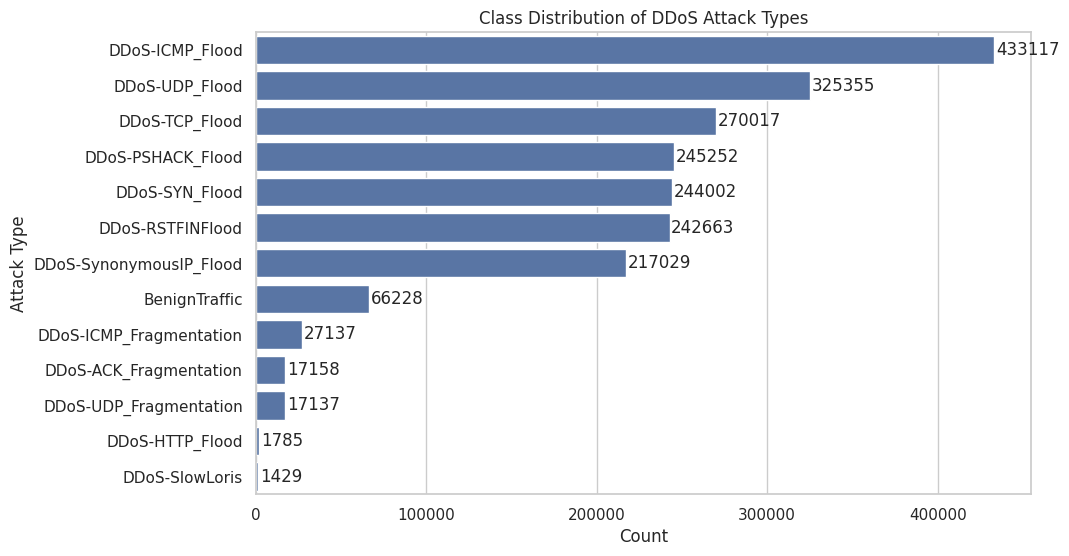

In [ ]:
plt.figure(figsize=(10,6))
ax = sns.countplot(y=df['label'], order=df['label'].value_counts().index)

for i, v in enumerate(df['label'].value_counts().values):
    ax.text(v + 1000, i, str(v), va='center')

plt.title("Class Distribution of DDoS Attack Types")
plt.xlabel("Count")
plt.ylabel("Attack Type")
plt.show()

Step 9: Histograms (Feature Distribution)

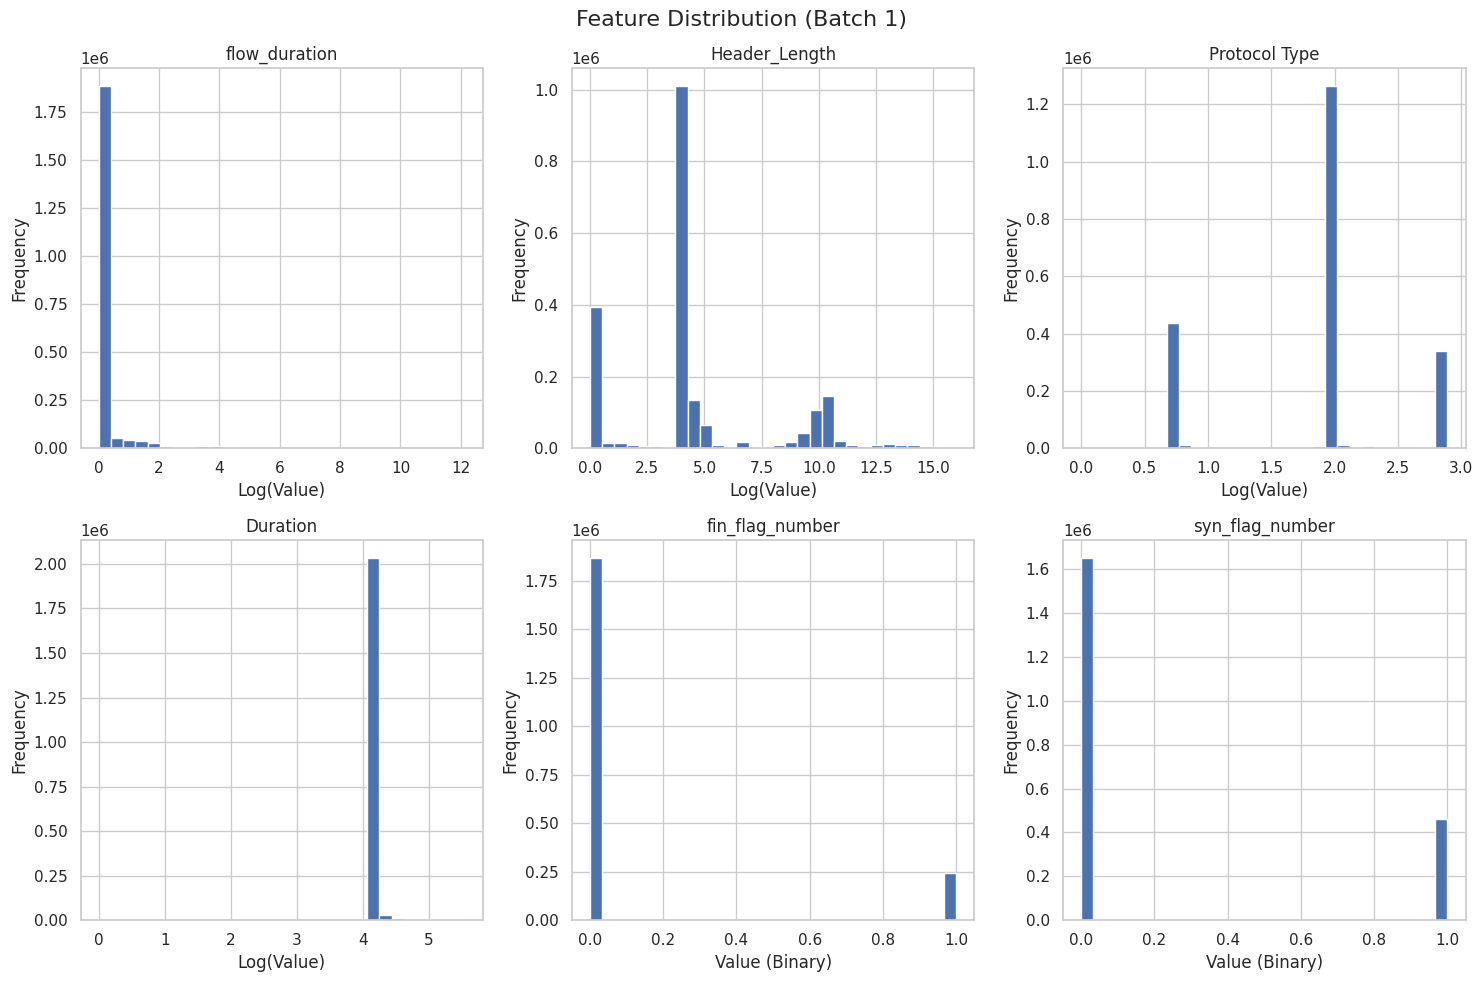

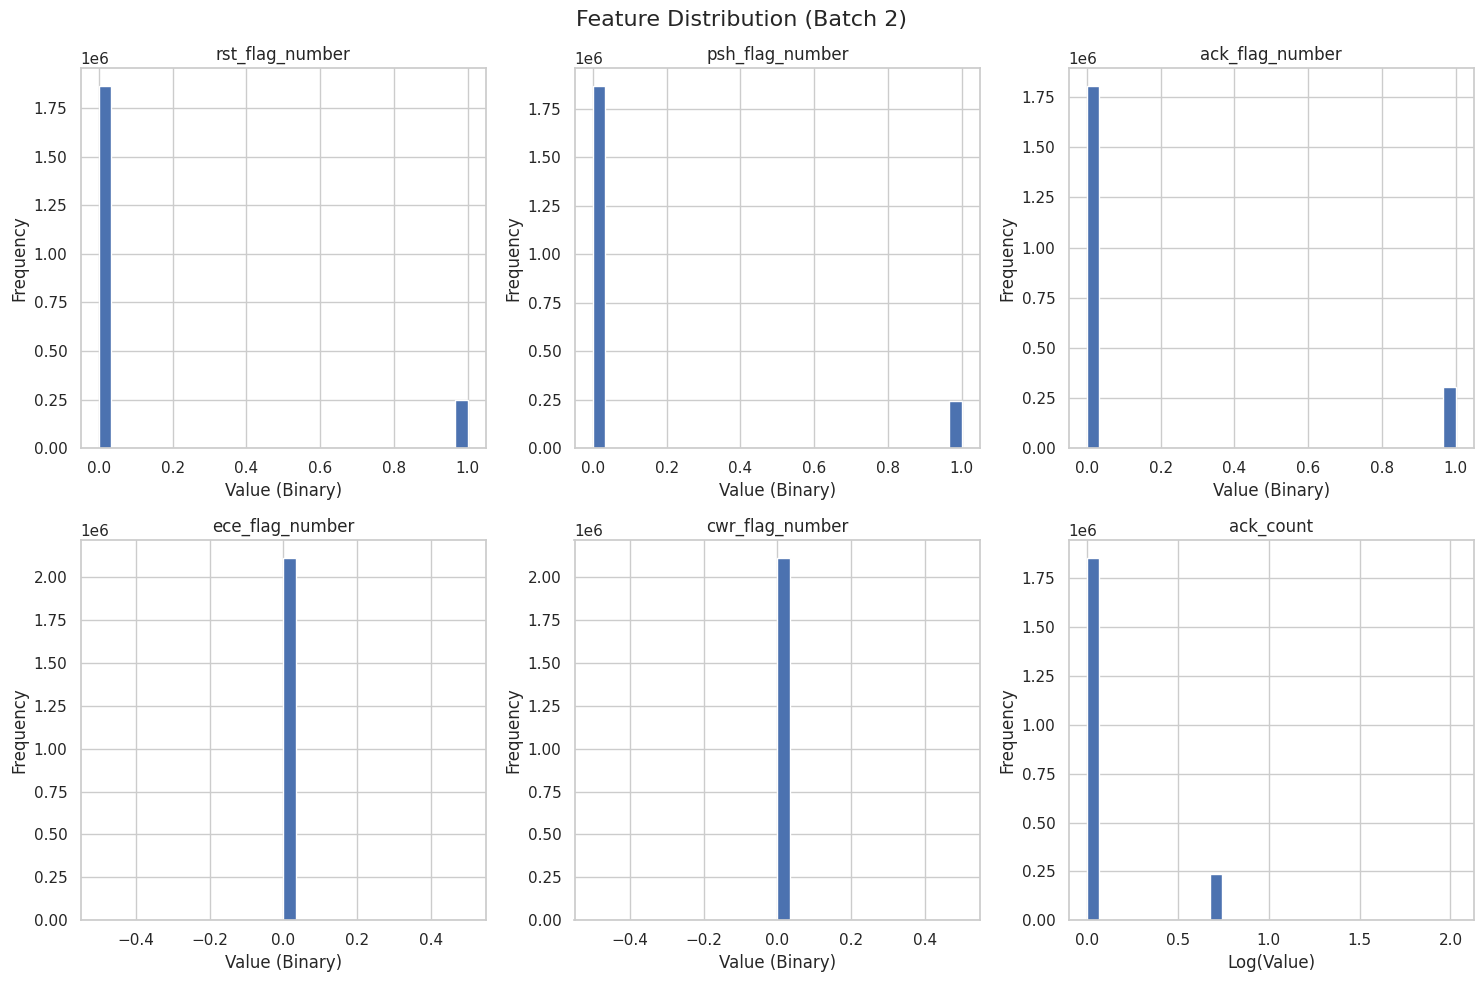

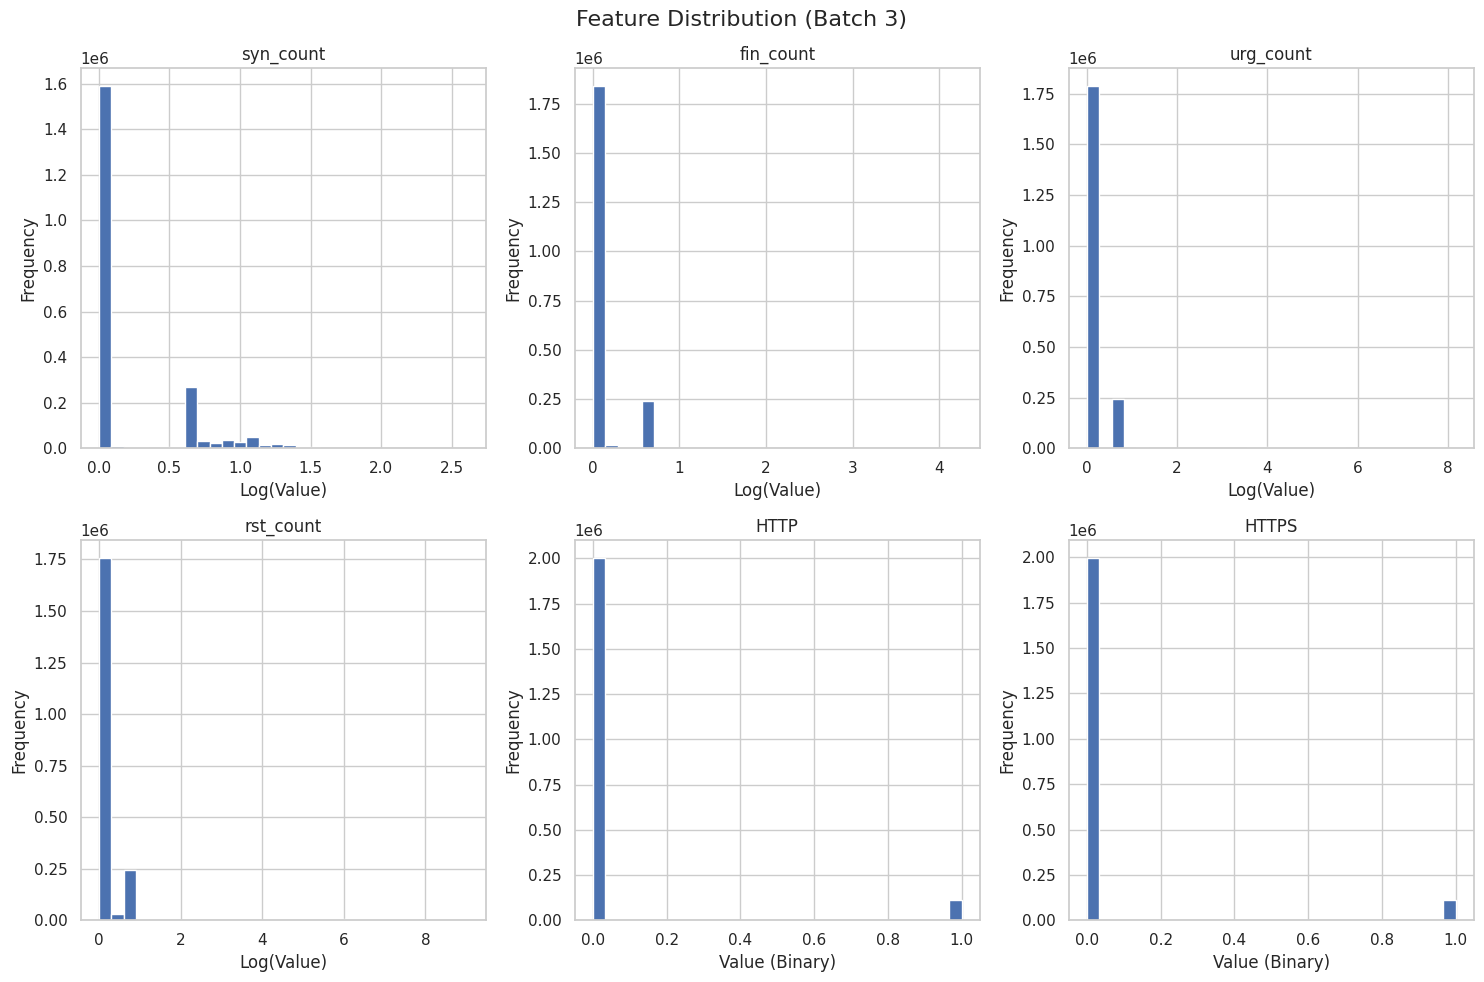

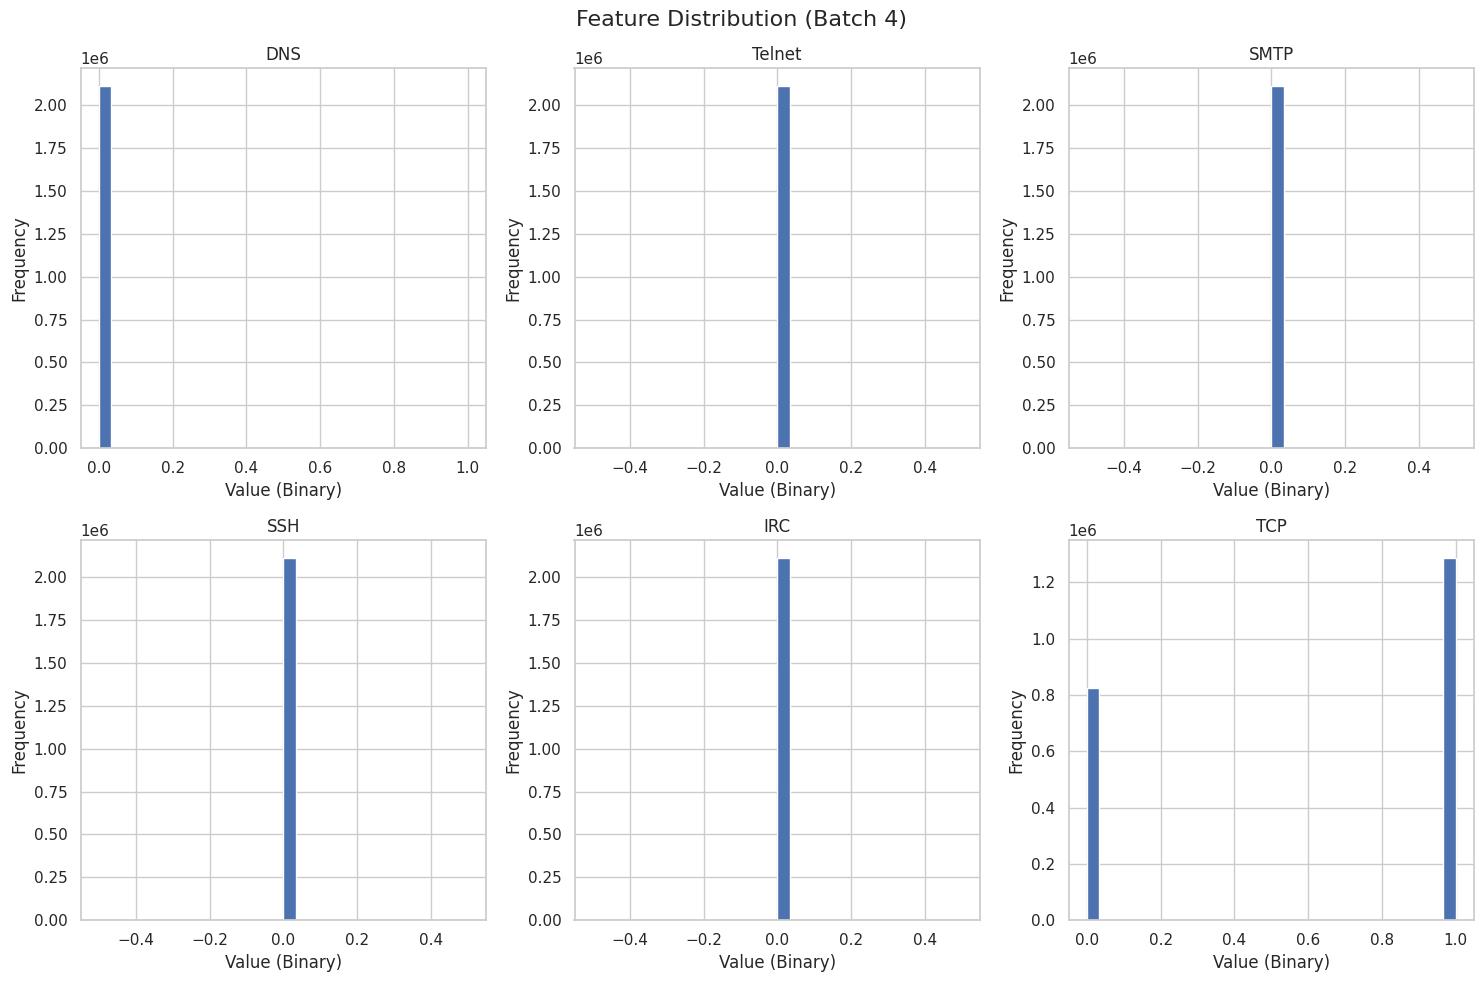

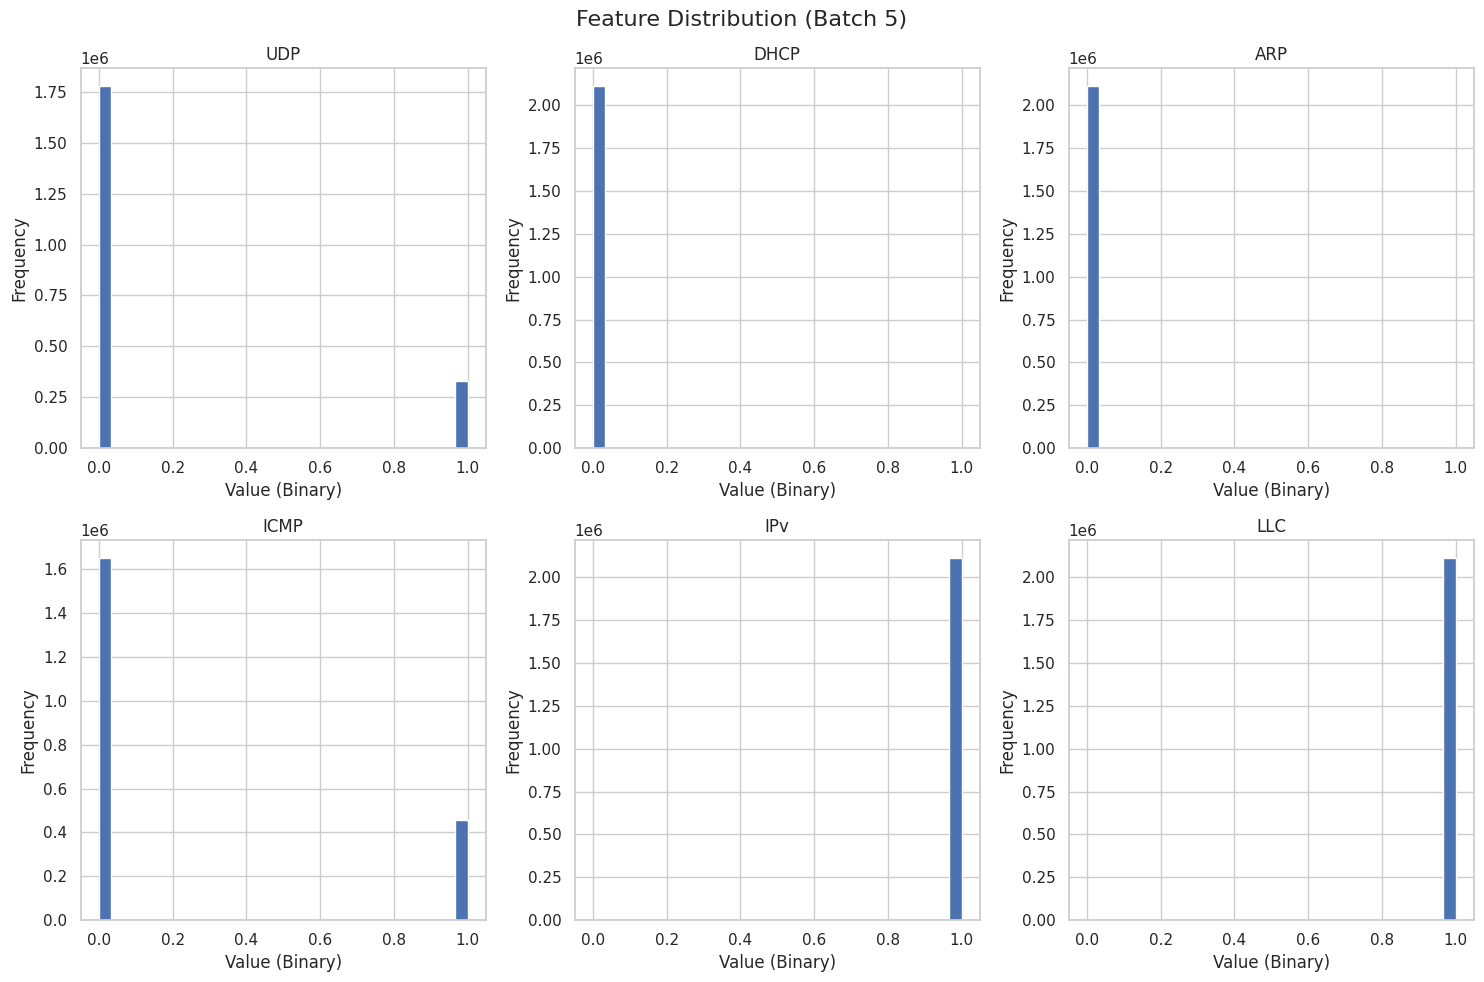

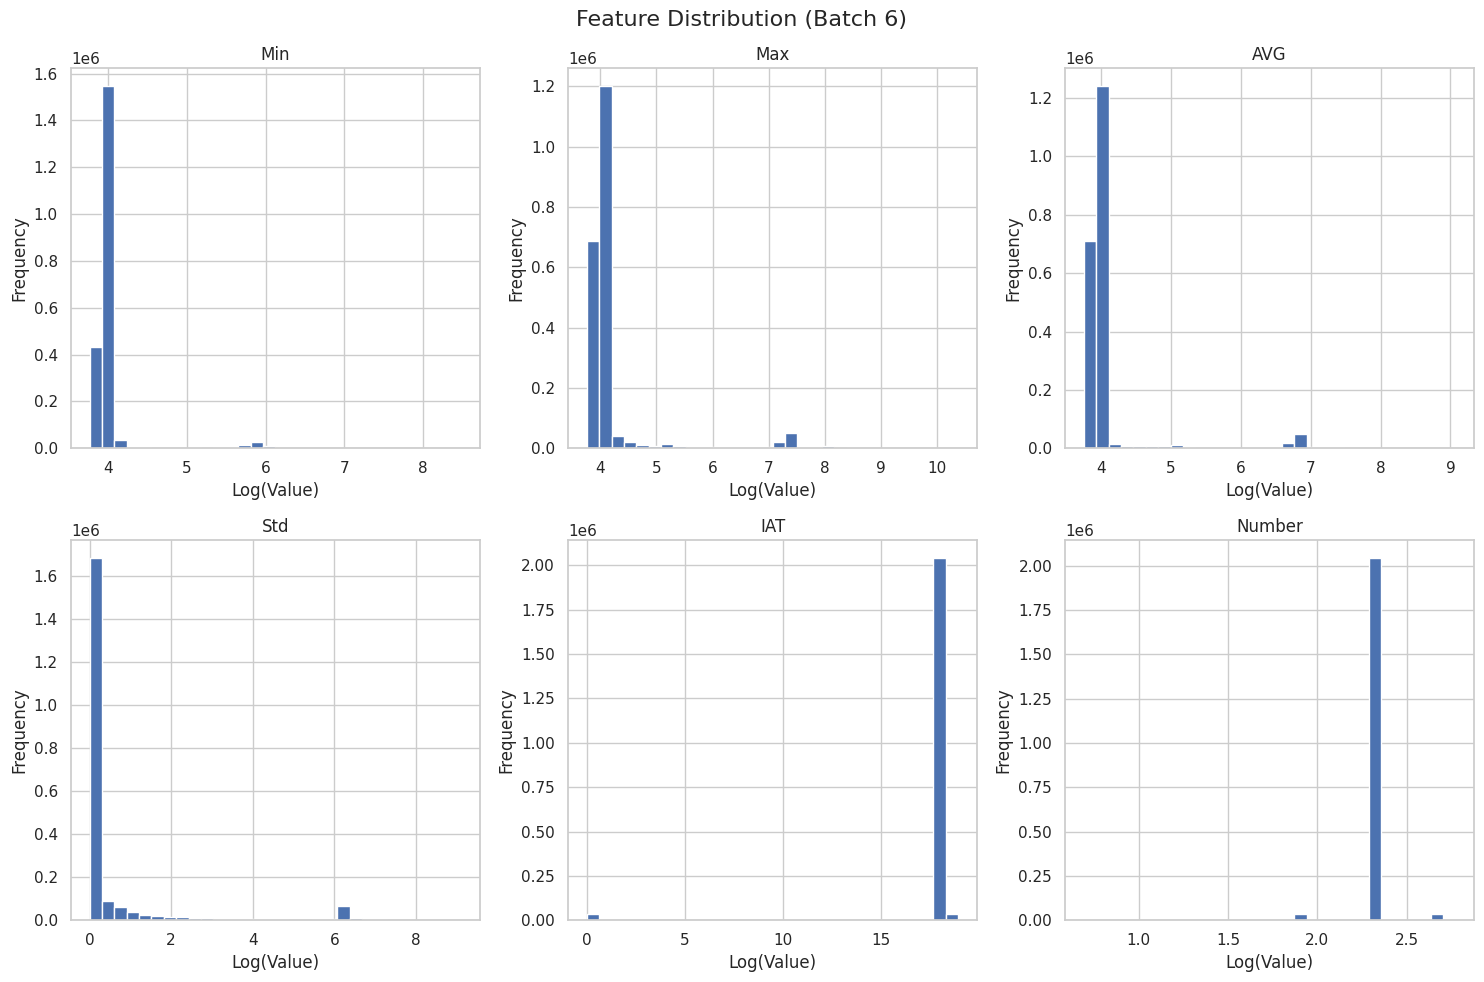

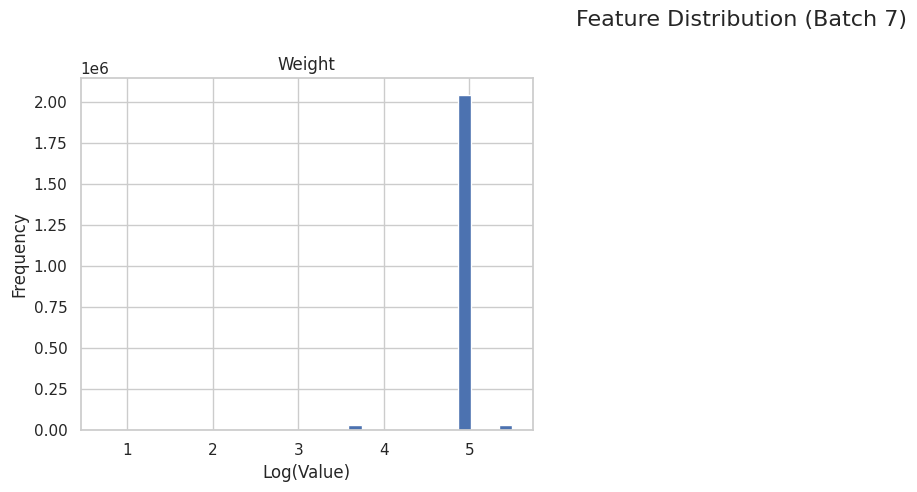

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math

features = X.columns
num_features = len(features)

batch_size = 6  # plots per figure

for i in range(0, num_features, batch_size):
    subset = features[i:i+batch_size]
    n = len(subset)

    rows = math.ceil(n / 3)  # dynamic rows

    plt.figure(figsize=(15, 5 * rows))

    for j, col in enumerate(subset):
        plt.subplot(rows, 3, j+1)

        # Apply log only if needed
        if X[col].nunique() > 2:
            data = np.log1p(X[col])
            xlabel = "Log(Value)"
        else:
            data = X[col]
            xlabel = "Value (Binary)"

        plt.hist(data, bins=30)
        plt.title(col)
        plt.xlabel(xlabel)
        plt.ylabel("Frequency")

    plt.suptitle(f"Feature Distribution (Batch {i//batch_size + 1})", fontsize=16)
    plt.tight_layout()
    plt.show()

Step 10: Log Scale Boxplot (Outlier Analysis)

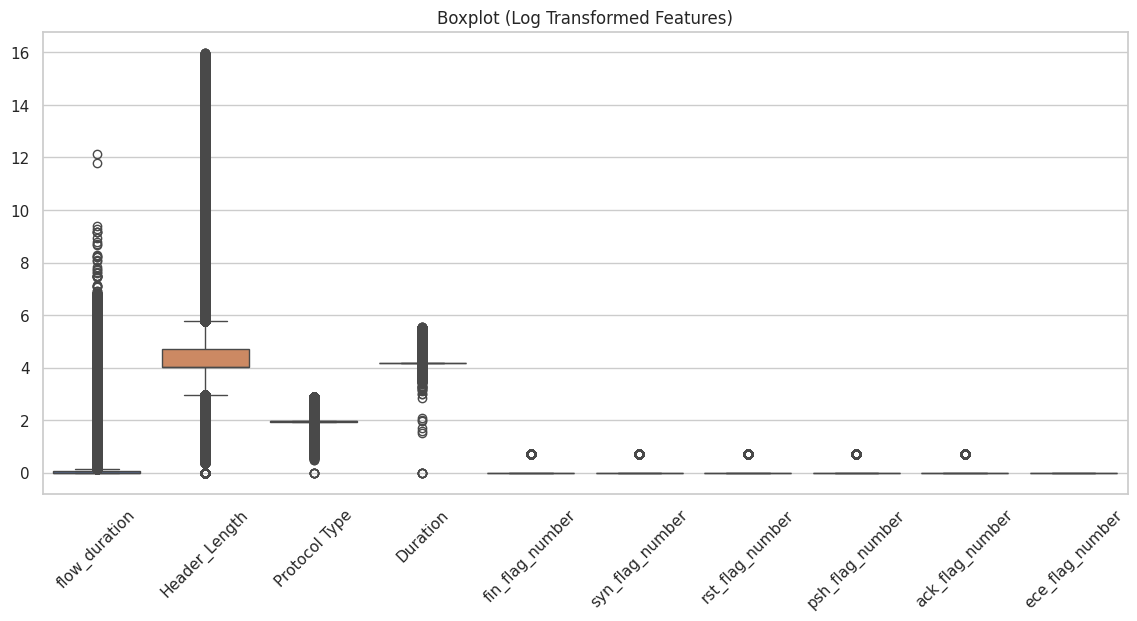

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply log transform (avoid log(0))
X_log = np.log1p(X.iloc[:, :10])

plt.figure(figsize=(14,6))
sns.boxplot(data=X_log)

plt.title("Boxplot (Log Transformed Features)")
plt.xticks(rotation=45)
plt.show()

Step 11: Outlier Analysis - IQR Method

Continuous features: 16
Binary features: 21

Top Outlier Features:

          Feature  Outlier_Count  Outlier_Percentage
2   Protocol Type         935526           44.373287
10            Max         632925           30.020505
11            AVG         581459           27.579401
9             Min         553754           26.265315
5       syn_count         512485           24.307869
3        Duration         478187           22.681068
8       rst_count         465453           22.077077
12            Std         464538           22.033677
1   Header_Length         451460           21.413370
7       urg_count         437314           20.742405
0   flow_duration         357311           16.947753
6       fin_count         318633           15.113202
4       ack_count         303889           14.413874
13            IAT          70341            3.336371
15         Weight          68217            3.235626


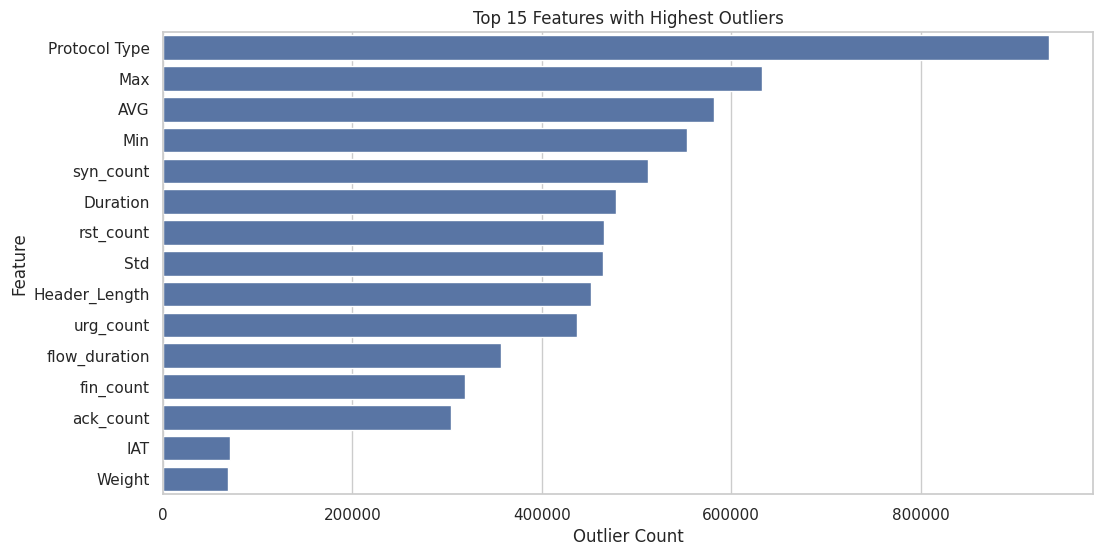

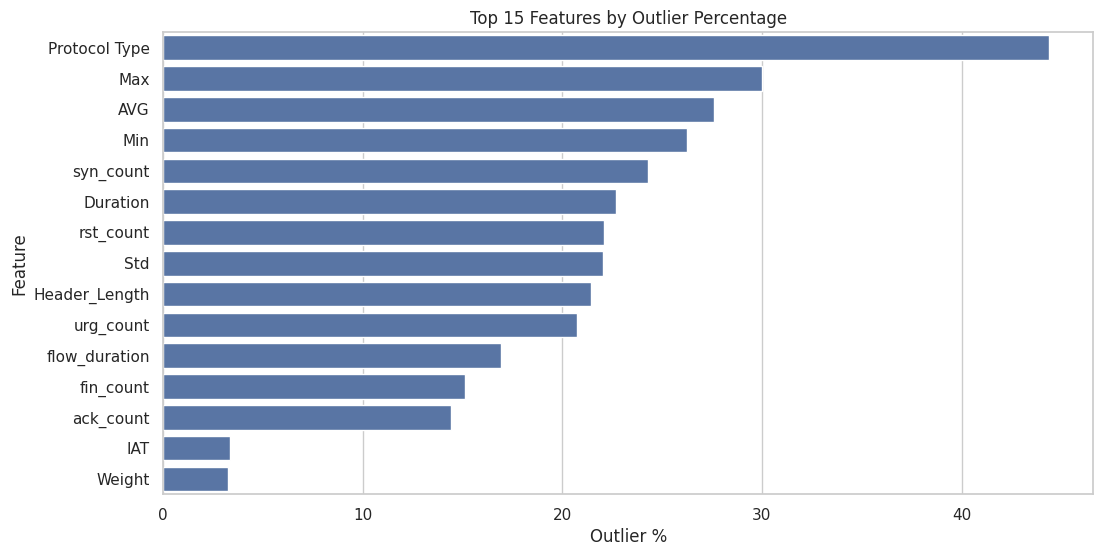

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Separate feature types

continuous_cols = [col for col in X.columns if X[col].nunique() > 10]
binary_cols = [col for col in X.columns if X[col].nunique() <= 2]

print("Continuous features:", len(continuous_cols))
print("Binary features:", len(binary_cols))

# 2. IQR Outlier Calculation (ONLY CONTINUOUS)

outlier_summary = {}

for col in continuous_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((X[col] < lower_bound) | (X[col] > upper_bound)).sum()

    outlier_summary[col] = outliers

# Convert to DataFrame
outlier_df = pd.DataFrame(
    list(outlier_summary.items()),
    columns=['Feature', 'Outlier_Count']
)

# Add percentage
outlier_df['Outlier_Percentage'] = (outlier_df['Outlier_Count'] / len(X)) * 100

# Sort
outlier_df = outlier_df.sort_values(by='Outlier_Count', ascending=False)

print("\nTop Outlier Features:\n")
print(outlier_df.head(15))


# 3. Visualization (Top 15)

plt.figure(figsize=(12,6))

sns.barplot(
    data=outlier_df.head(15),
    x='Outlier_Count',
    y='Feature'
)

plt.title("Top 15 Features with Highest Outliers")
plt.xlabel("Outlier Count")
plt.ylabel("Feature")
plt.show()

# 4. Percentage Visualization

plt.figure(figsize=(12,6))

sns.barplot(
    data=outlier_df.head(15),
    x='Outlier_Percentage',
    y='Feature'
)

plt.title("Top 15 Features by Outlier Percentage")
plt.xlabel("Outlier %")
plt.ylabel("Feature")
plt.show()

# exclude categorical like features
categorical_like = ['Protocol Type']

continuous_cols = [
    col for col in X.columns
    if X[col].nunique() > 10 and col not in categorical_like
]

Step 12: Correlation Study

Total Continuous Features: 16


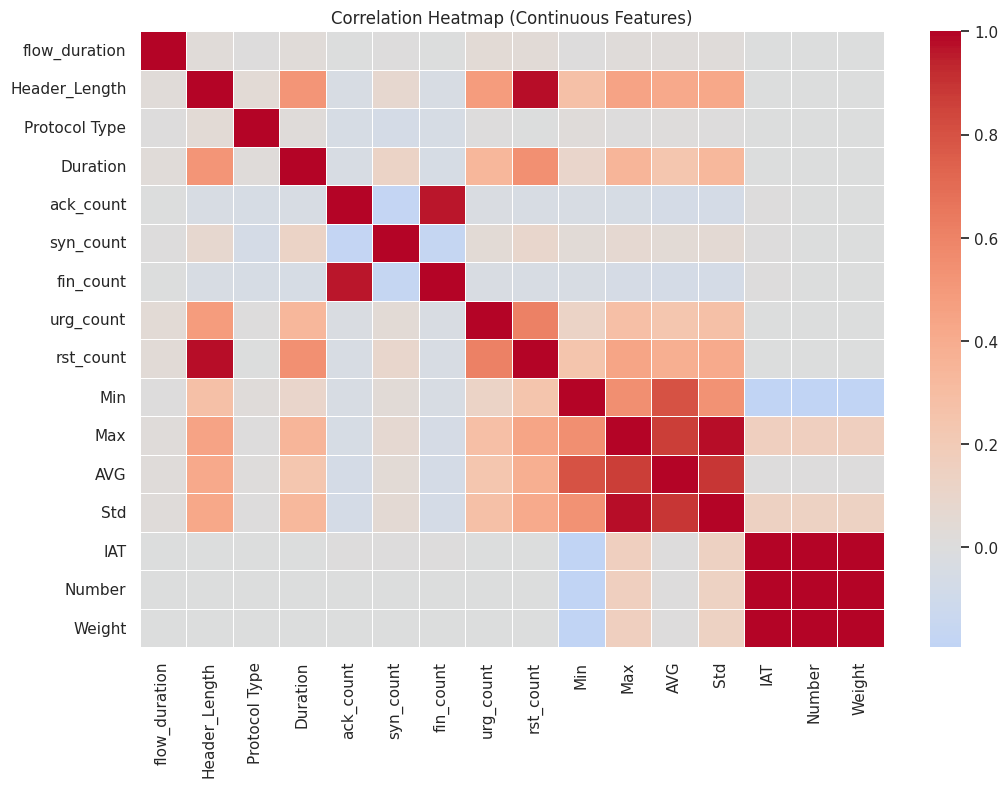

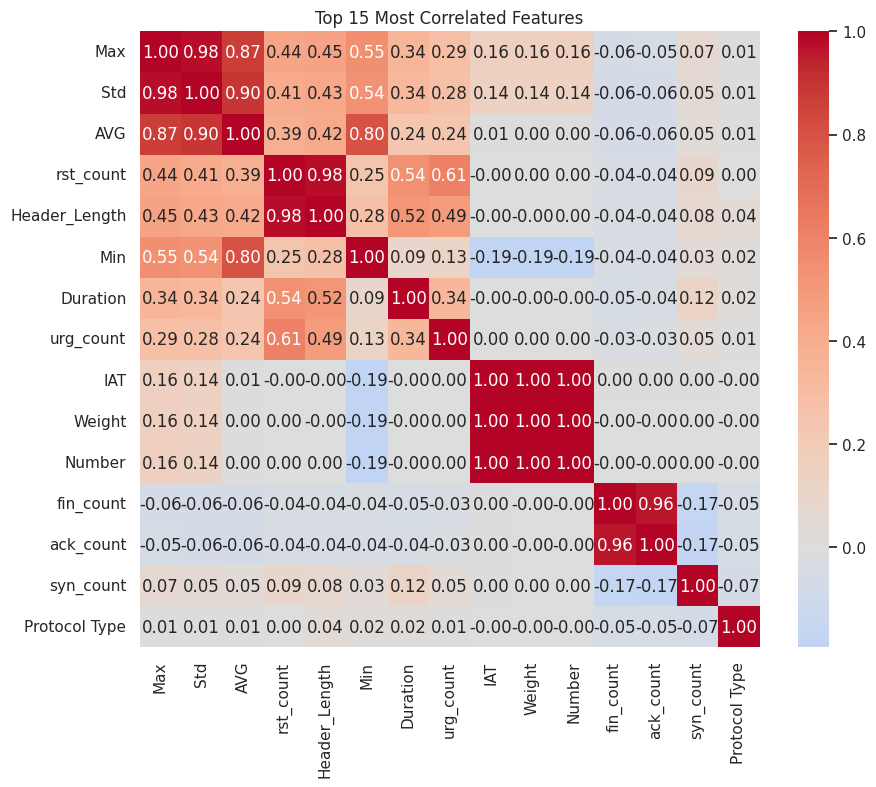


Top 15 Strong Feature Correlations:

Number         Weight           0.999558
Weight         Number           0.999558
               IAT              0.997317
IAT            Weight           0.997317
               Number           0.995900
Number         IAT              0.995900
Header_Length  rst_count        0.978708
rst_count      Header_Length    0.978708
Max            Std              0.977846
Std            Max              0.977846
fin_count      ack_count        0.958801
ack_count      fin_count        0.958801
AVG            Std              0.896716
Std            AVG              0.896716
Max            AVG              0.873015
dtype: float64

Highly Correlated Feature Pairs (>0.85):

Number         Weight           0.999558
Weight         Number           0.999558
               IAT              0.997317
IAT            Weight           0.997317
               Number           0.995900
Number         IAT              0.995900
Header_Length  rst_count        0.978708
rs

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Select only continuous features

continuous_cols = [col for col in X.columns if X[col].nunique() > 10]

X_cont = X[continuous_cols]

print("Total Continuous Features:", len(continuous_cols))


# 2. Correlation Matrix

corr_matrix = X_cont.corr()

# 3. Full Heatmap (Clean)

plt.figure(figsize=(12,8))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap (Continuous Features)")
plt.show()

# 4. Top Correlated Features Heatmap (Focused)

top_features = corr_matrix.abs().sum().sort_values(ascending=False).head(15).index

plt.figure(figsize=(10,8))

sns.heatmap(
    X_cont[top_features].corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Top 15 Most Correlated Features")
plt.show()

# 5. Extract Strong Correlations (Pairs)

corr_pairs = corr_matrix.abs().unstack()

# Remove self-correlation
corr_pairs = corr_pairs[corr_pairs < 1]

# Sort
strong_corr = corr_pairs.sort_values(ascending=False)

print("\nTop 15 Strong Feature Correlations:\n")
print(strong_corr.head(15))


# 6. Filter Highly Correlated Features (> 0.85)

threshold = 0.85

high_corr = strong_corr[strong_corr > threshold]

print(f"\nHighly Correlated Feature Pairs (>{threshold}):\n")
print(high_corr)


# 7. Drop Highly Correlated Features


to_drop = set()

for (f1, f2), corr_value in high_corr.items():
    to_drop.add(f2)  # drop second feature

print("\nFeatures suggested to drop (due to redundancy):\n")
print(to_drop)

Step 14: Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd


# 1. Define Input and Output

X_final = X.copy()
y_final = y.copy()

print("Original Dataset Shape:")
print("X:", X_final.shape)
print("y:", y_final.shape)


# 2. Stratified Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X_final,
    y_final,
    test_size=0.2,
    stratify=y_final,   # IMPORTANT for class balance
    random_state=42
)

# 3. Verify Shapes

print("\nAfter Train-Test Split:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# 4. Verify Class Distribution

print("\nClass Distribution (Train):")
print(pd.Series(y_train).value_counts(normalize=True))

print("\nClass Distribution (Test):")
print(pd.Series(y_test).value_counts(normalize=True))

Original Dataset Shape:
X: (2108309, 37)
y: (2108309,)

After Train-Test Split:
X_train: (1686647, 37)
X_test : (421662, 37)
y_train: (1686647,)
y_test : (421662,)

Class Distribution (Train):
label_encoded
3     0.205433
11    0.154320
10    0.128073
5     0.116327
7     0.115734
6     0.115098
9     0.102940
0     0.031413
4     0.012872
1     0.008138
12    0.008129
2     0.000847
8     0.000678
Name: proportion, dtype: float64

Class Distribution (Test):
label_encoded
3     0.205435
11    0.154320
10    0.128072
5     0.116325
7     0.115733
6     0.115099
9     0.102940
0     0.031414
4     0.012870
1     0.008139
12    0.008127
2     0.000847
8     0.000678
Name: proportion, dtype: float64


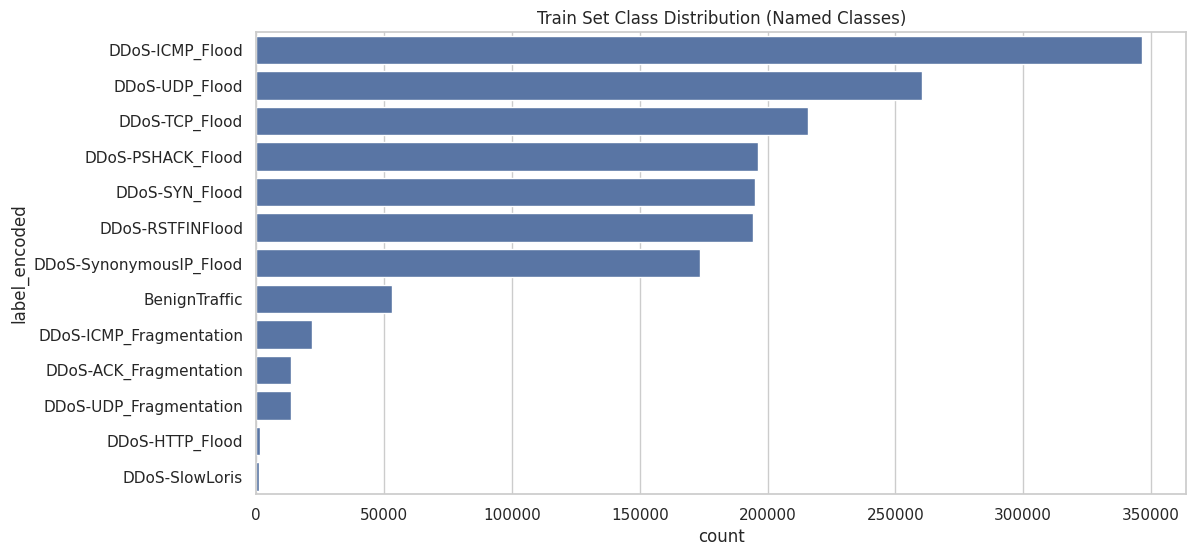

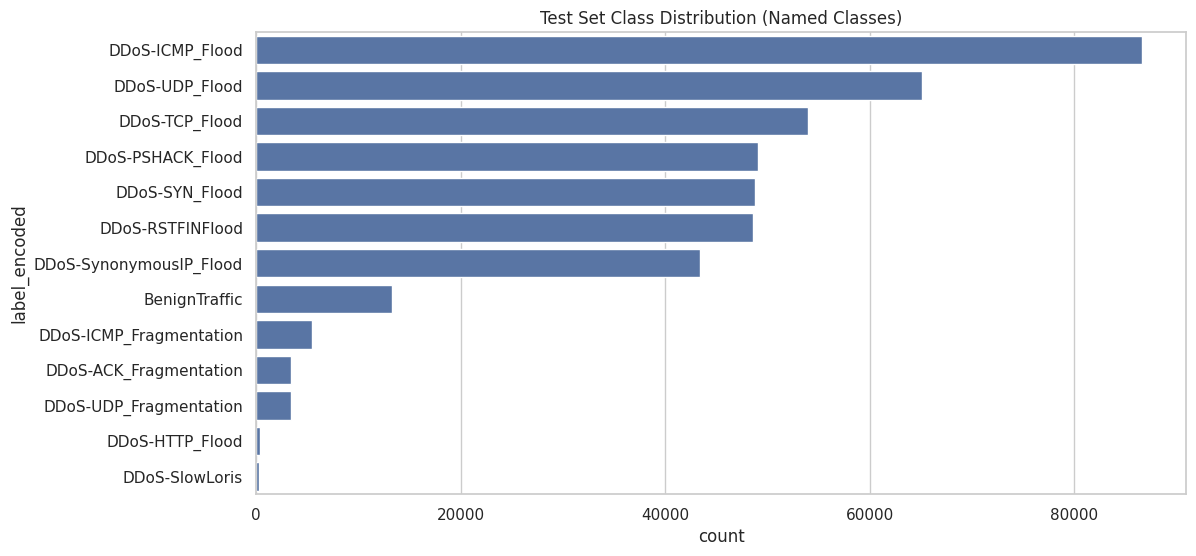

In [ ]:
# Reverse mapping
label_map = dict(enumerate(le.classes_))

y_train_named = pd.Series(y_train).map(label_map)
y_test_named = pd.Series(y_test).map(label_map)

plt.figure(figsize=(12,6))
sns.countplot(y=y_train_named, order=y_train_named.value_counts().index)
plt.title("Train Set Class Distribution (Named Classes)")
plt.show()

plt.figure(figsize=(12,6))
sns.countplot(y=y_test_named, order=y_test_named.value_counts().index)
plt.title("Test Set Class Distribution (Named Classes)")
plt.show()

Step 15: Handle Class Imbalance (SMOTE Analysis)

Before SMOTE: label_encoded
3     346493
11    260284
10    216014
5     196202
7     195202
6     194130
9     173623
0      52982
4      21710
1      13726
12     13710
2       1428
8       1143
Name: count, dtype: int64

After SMOTE: label_encoded
10    346493
9     346493
5     346493
3     346493
6     346493
7     346493
11    346493
4     346493
0     346493
12    346493
8     346493
1     346493
2     346493
Name: count, dtype: int64


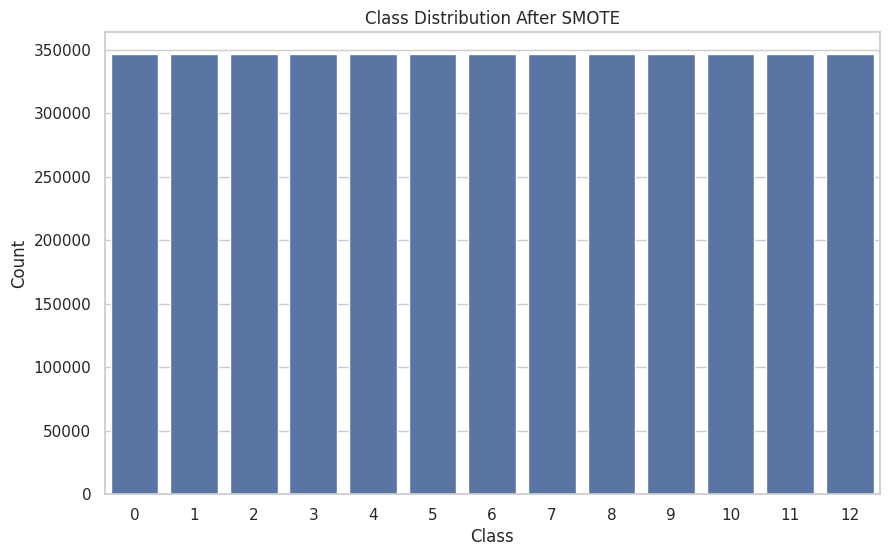

Class Weights: {np.int64(0): np.float64(2.4487953818858657), np.int64(1): np.float64(9.452285948060391), np.int64(2): np.float64(90.85579616461969), np.int64(3): np.float64(0.37444357295263375), np.int64(4): np.float64(5.976143570846473), np.int64(5): np.float64(0.6612678613015001), np.int64(6): np.float64(0.6683257452381235), np.int64(7): np.float64(0.6646554693244788), np.int64(8): np.float64(113.51012854162461), np.int64(9): np.float64(0.7472631904936381), np.int64(10): np.float64(0.6006188345342289), np.int64(11): np.float64(0.4984635126364929), np.int64(12): np.float64(9.46331706222297)}


In [ ]:
# STEP 15A: SMOTE (Oversampling)

from imblearn.over_sampling import SMOTE

print("Before SMOTE:", pd.Series(y_train).value_counts())

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nAfter SMOTE:", pd.Series(y_train_smote).value_counts())

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
sns.countplot(x=y_train_smote)
plt.title("Class Distribution After SMOTE")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

# STEP 15B: CLASS WEIGHT

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Step 16: Feature Scaling and Final Prerocessing

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train_smote)

# Transform test data
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

# Check mean ≈ 0 and std ≈ 1
print("Mean (approx):", X_train_scaled.mean())
print("Std (approx):", X_train_scaled.std())

Scaled Training Shape: (4504409, 37)
Scaled Testing Shape: (421662, 37)
Mean (approx): -5.777853009400917e-16
Std (approx): 0.9153348228041152


Step 17: Baseline model

===== BASELINE MODEL RESULTS =====
Accuracy: 0.9578
ROC-AUC (OvR): 0.9976

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.82      0.88     13246
           1       0.90      0.98      0.94      3432
           2       0.23      0.93      0.36       357
           3       1.00      1.00      1.00     86624
           4       1.00      0.98      0.99      5427
           5       1.00      1.00      1.00     49050
           6       1.00      1.00      1.00     48533
           7       0.79      0.95      0.87     48800
           8       0.09      0.70      0.16       286
           9       0.96      0.72      0.82     43406
          10       1.00      1.00      1.00     54003
          11       1.00      1.00      1.00     65071
          12       0.97      0.99      0.98      3427

    accuracy                           0.96    421662
   macro avg       0.84      0.93      0.85    421662
weighted avg       0.97      0.96  

<Figure size 1200x1000 with 0 Axes>

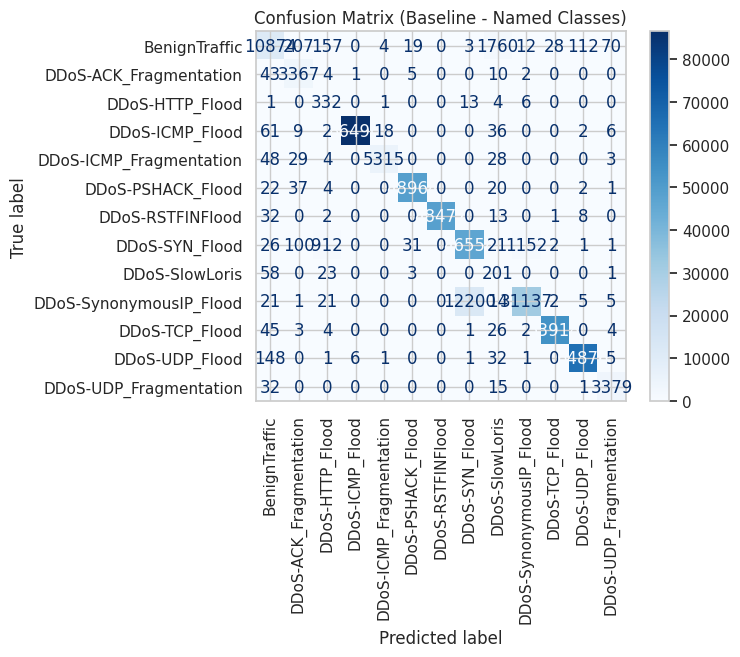

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
import matplotlib.pyplot as plt
import numpy as np

# Initialize model
baseline_model = LogisticRegression(
    max_iter=200,
    n_jobs=-1
)

# Train
baseline_model.fit(X_train_scaled, y_train_smote)

# Predict
y_pred = baseline_model.predict(X_test_scaled)
y_prob = baseline_model.predict_proba(X_test_scaled)

# ===============================
# METRICS
# ===============================

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob, multi_class='ovr')

print("===== BASELINE MODEL RESULTS =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"ROC-AUC (OvR): {roc_auc:.4f}\n")

print("Classification Report:\n")
print(classification_report(y_test, y_pred))

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use original class names
labels = le.classes_

plt.figure(figsize=(12,10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=labels,
    xticks_rotation=90,
    cmap='Blues'
)

plt.title("Confusion Matrix (Baseline - Named Classes)")
plt.show()

Step 18: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score
)
import matplotlib.pyplot as plt
import time


# 1. Model (FAST CONFIG)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    n_jobs=-1,
    random_state=42
)

# 2. Train

start = time.time()
rf_model.fit(X_train_scaled, y_train_smote)
train_time = time.time() - start

# 3. Predict

start = time.time()
y_pred_rf = rf_model.predict(X_test_scaled)
y_prob_rf = rf_model.predict_proba(X_test_scaled)
test_time = time.time() - start

# 4. Metrics

accuracy = accuracy_score(y_test, y_pred_rf)
roc_auc = roc_auc_score(y_test, y_prob_rf, multi_class='ovr')

print("===== RANDOM FOREST RESULTS =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"ROC-AUC (OvR): {roc_auc:.4f}")
print(f"Training Time: {train_time:.2f} sec")
print(f"Inference Time: {test_time:.2f} sec\n")

print("Classification Report:\n")
print(classification_report(y_test, y_pred_rf))

# 5. CONFUSION MATRIX (NAMED + NORMALIZED)

labels = le.classes_

plt.figure(figsize=(12,10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=labels,
    xticks_rotation=90,
    cmap='Greens',
    normalize='true'
)

plt.title("Normalized Confusion Matrix - Random Forest")
plt.show()